# D-FINE-L (Query-Based Detector)

Fine-tunes D-FINE-L (pretrained on Objects365 and COCO, Hugging Face `transformers`) on VisDrone and evaluates it
with the shared COCO protocol (sequence-held-out validation split, every 3rd frame, ignored regions treated as "don't care").

Sections:
1. Setup
2. Configuration
3. Training (resumes automatically from the last saved epoch)
4. Training curves
5. Validation metrics
6. Kaggle submission

## 1. Setup

Set `RUNTIME` to `"colab"` (checkpoints go to Google Drive) or `"local"` (checkpoints go to `runs/`).
On Colab, upload `kaggle.json` to the session first so the dataset can be downloaded.

In [1]:
RUNTIME = "local"  # "colab" or "local"
REPO_URL = "https://github.com/rudkoLA/ai-hw-2-rudko-omelianchuk.git"

In [2]:
import os
import subprocess
import sys
from pathlib import Path

if RUNTIME == "colab":
    repo_dir = Path("/content/ai-hw-2-rudko-omelianchuk")
    if not repo_dir.exists():
        subprocess.run(["git", "clone", REPO_URL, str(repo_dir)], check=True)
    os.chdir(repo_dir)
    uploaded_key = Path("/content/kaggle.json")
    if uploaded_key.exists():
        kaggle_key = Path.home() / ".kaggle" / "kaggle.json"
        kaggle_key.parent.mkdir(parents=True, exist_ok=True)
        kaggle_key.write_bytes(uploaded_key.read_bytes())
        kaggle_key.chmod(0o600)
    subprocess.run(
        [sys.executable, "-m", "pip", "install", "-q", "transformers", "ultralytics", "pycocotools", "kaggle"],
        check=True,
    )

print(f"Working directory: {Path.cwd()}")

Working directory: c:\Users\Kyrylo\Desktop\ai-hw-2-rudko-omelianchuk


In [3]:
import pandas as pd

from src.dfine import evaluate_dfine, load_dfine, predict_frames, train_dfine
from src.setup_utils import ensure_dataset, resolve_storage, setup_environment
from src.submission import build_submission, load_test_frames, submit_to_kaggle, validate_submission
from src.ultralytics_utils import plot_training_curves

env = setup_environment(seed=42, mount_gdrive=False)
device = env["device"]
dataset_dir, coco_train, coco_val, class_names = ensure_dataset()
del coco_train, coco_val  # the datasets load their own annotations
storage = resolve_storage(RUNTIME, "dfine")

[Environment]: CUDA GPU (AMD Radeon RX 7800 XT, 16.0 GB VRAM) -> Mixed Precision (AMP Enabled)
[Dataset]: Resolved dataset root at -> dataset
[Storage]: local -> C:\Users\Kyrylo\Desktop\ai-hw-2-rudko-omelianchuk\runs\dfine


## 2. Configuration

All tunable parameters. `model_config` overrides fields of the Hugging Face `DFineConfig`
(any other `DFineConfig` field can be added there).
Give every experiment its own `run_name`: an existing run with the same name is resumed (or skipped if finished).

Changes from the D-FINE-M run (`dfine_m_1024`, 0.307 public LB):
- **D-FINE-L** (`dfine-large-obj2coco-e25`) instead of M.
- **16:9 input `(768, 1344)`** instead of a 1024x1024 letterbox: about the same pixel count, but most VisDrone
  frames are 16:9, so far less of the input is padding and objects get ~31% more pixels per side.
- **Augmentation**: no rotation (it loosens axis-aligned boxes), `RandomZoomCrop` on the original image
  (objects up to 2x larger), and the last `no_aug_epochs` epochs train with flips only.
- **`mask_ignore=True`**: objects inside ignored regions are no longer trained as background.
- **Input `(896, 1600)` + `downscale_p=0.2`** (run `dfine_l_896x1600_ds`, after `dfine_l_768x1344`: 30 min/epoch, 9 GB):
  the test set has a different resolution mix from train/val. 66% of test frames are at most 1360 px wide
  (1360x764, 1344x756, 960x540, 680x382; the last two never occur in training) and are upscaled by the
  letterbox, while training frames are mostly 1904-2688 px wide and 34% of validation frames are 4K.
  `downscale_p` shrinks and re-enlarges 20% of training images so the model also sees blurry upscaled frames.
  Validation mAP likely overstates the test gain from the larger input.
- **Schedule**: 10 epochs with the cosine decay reaching its minimum at the end, lr 5e-5 (backbone x0.05),
  EMA decay 0.9998. Early stopping is effectively off (`patience >= epochs`) so the cosine schedule completes.

**Batch size**: the training progress bar shows `mem` (peak reserved GPU memory). On a 16 GB card start with
`batch=4`; raise it if `mem` stays below ~13 GB, lower it on OOM. `accumulate` sums gradients over several
batches (effective batch = `batch * accumulate`); scale `lr0` roughly linearly if you change the effective batch.

`QUICK_TEST = True` trains on a 10% sample of every 15th frame for 10 epochs, for fast comparisons
between settings; its runs get a `_quick` suffix. Use `QUICK_TEST = False` for the final run.

In [4]:
CFG = {
    "run_name": "dfine_l_896x1600_ds",
    "checkpoint": "ustc-community/dfine-large-obj2coco-e25",  # D-FINE-L, Objects365 + COCO pretrained
    "class_names": class_names,
    "train_stride": 3,             # every n-th frame of each training sequence
    "val_stride": 3,               # every n-th frame of each validation sequence
    "fraction": 1.0,               # fraction of the selected training frames to use
    # Schedule
    "imgsz": [896, 1600],          # (H, W), multiples of 32; or an int for a square input
    "epochs": 10,
    "batch": 4,                    # per step; tune with the `mem` readout (see above)
    "accumulate": 1,               # gradient accumulation: effective batch = batch * accumulate
    "patience": 10,                # early stopping (epochs without val mAP improvement); >= epochs disables it
    "lr0": 5e-5,
    "backbone_lr_mult": 0.05,      # backbone LR = lr0 * backbone_lr_mult (official D-FINE-L ratio)
    "weight_decay": 1e-4,
    "warmup_iters": 500,            # optimizer steps
    "lr_min_ratio": 0.05,          # cosine decay to lr0 * lr_min_ratio
    "clip_grad_norm": 0.1,         # 0 disables gradient clipping
    "ema_decay": 0.9998,           # 0 disables the weight EMA
    "ema_warmups": 1000,
    "amp": True,                   # mixed precision (CUDA only)
    # Model (DFineConfig fields)
    "model_config": {
        "num_queries": 300,
        "num_denoising": 100,      # 0 disables denoising training
        "matcher_class_cost": 2.0,
        "matcher_bbox_cost": 5.0,
        "matcher_giou_cost": 2.0,
        "weight_loss_vfl": 1.0,
        "weight_loss_bbox": 5.0,
        "weight_loss_giou": 2.0,
        "weight_loss_fgl": 0.15,   # fine-grained localization loss
        "weight_loss_ddf": 1.5,    # decoupled distillation focal loss (self-distillation)
    },
    # Data
    "mask_ignore": True,           # fill ignored regions of training images with gray
    "zoom_crop_p": 0.5,            # probability of RandomZoomCrop (0 disables it)
    "zoom_crop_scale": [0.5, 1.0], # crop side as a fraction of the original image side
    "no_aug_epochs": 2,            # last epochs train with horizontal flips (and downscale) only
    "downscale_p": 0.2,            # imitate low-resolution test frames (see section 2)
    # Inference
    "max_det": 500,
    # Misc
    "workers": 4,
    "seed": 42,
}

QUICK_TEST = False
if QUICK_TEST:
    CFG.update({
        "run_name": CFG["run_name"] + "_quick",
        "train_stride": 15,
        "fraction": 0.1,
        "epochs": 10,
        "patience": 3,
    })

## 3. Training

Every epoch the EMA weights are evaluated on the validation frames; `last.pt`, `results.csv` and (on a new best
mAP@[.5:.95]) `best/` are written to `storage/<run_name>`.
Re-running this cell after an interruption resumes from `last.pt`; a finished run is not retrained.

In [5]:
run_dir = storage / CFG["run_name"]
train_dfine(CFG, dataset_dir, run_dir, device)

Run 'dfine_l_896x1600_ds': resume
loading annotations into memory...
Done (t=0.30s)
creating index...
index created!
Train frames: 8,090 | Val frames: 951 | input 896x1600 (HxW) | batch 4 x accumulate 1


[transformers] You passed `num_labels=8` which is incompatible to the `id2label` map of length `80`.


Loading weights:   0%|          | 0/1197 [00:00<?, ?it/s]

[transformers] DFineForObjectDetection LOAD REPORT from: ustc-community/dfine-large-obj2coco-e25
Key                                                 | Status   |                                                                                        
----------------------------------------------------+----------+----------------------------------------------------------------------------------------
model.decoder.class_embed.{0, 1, 2, 3, 4, 5}.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([80]) vs model:torch.Size([8])          
model.denoising_class_embed.weight                  | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([81, 256]) vs model:torch.Size([9, 256])
model.enc_score_head.weight                         | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([80, 256]) vs model:torch.Size([8, 256])
model.enc_score_head.bias                           | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([80]) vs model:torch.Size(

Resuming from epoch 9/10 (best mAP 0.3031)
epoch 9: augmentation off (flip only) for the last 2 epoch(s)


epoch 9/10:   0%|          | 0/2023 [00:23<?, ?it/s]

... (3 outputs left out)

epoch 10/10:   0%|          | 0/2023 [00:00<?, ?it/s]

predict:   0%|          | 0/238 [00:00<?, ?it/s]

Loading and preparing results...
DONE (t=0.85s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *bbox*
DONE (t=58.12s).
Accumulating evaluation results...
DONE (t=2.63s).
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = -1.000
 Average Precision  (AP) @[ IoU=0.50      | area=   all | maxDets=500 ] = 0.569
 Average Precision  (AP) @[ IoU=0.75      | area=   all | maxDets=500 ] = 0.277
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= small | maxDets=500 ] = 0.154
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=medium | maxDets=500 ] = 0.278
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= large | maxDets=500 ] = 0.488
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=  1 ] = 0.180
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets= 10 ] = 0.392
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=500 ] = 0.525
 Average Recall     (AR) @[ IoU=0.50:0.95 | area= small | maxDets=

'resume'

## 4. Training curves

Per-epoch validation mAP and train / validation losses (each loss type summed over decoder layers,
encoder and denoising terms).

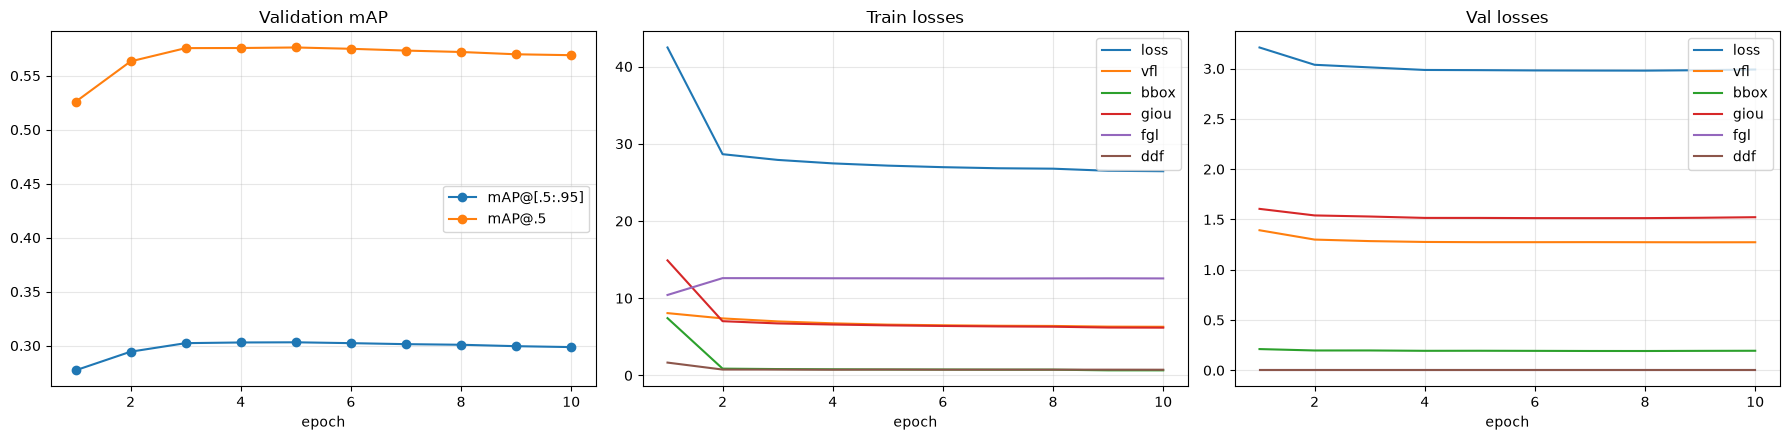

In [6]:
run_dir = storage / CFG["run_name"]
history = plot_training_curves(run_dir)

## 5. Validation metrics

The best weights are evaluated on the validation frames with `evaluate_coco_metrics`
(up to 500 detections per image, no NMS). Results are saved to `storage/<run_name>/metrics.json`.

In [7]:
best_model = load_dfine(run_dir / "best", device)
metrics = evaluate_dfine(
    best_model,
    dataset_dir,
    val_stride=CFG["val_stride"],
    imgsz=CFG["imgsz"],
    batch=CFG["batch"],
    max_det=CFG["max_det"],
    device=device,
    run_dir=run_dir,
    workers=CFG["workers"],
    amp=CFG["amp"],
)
pd.Series(metrics, name=CFG["run_name"]).round(4).to_frame()

Loading weights:   0%|          | 0/1197 [00:00<?, ?it/s]

predict:   0%|          | 0/238 [00:17<?, ?it/s]

loading annotations into memory...
Done (t=0.28s)
creating index...
index created!
Loading and preparing results...
DONE (t=0.66s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *bbox*
DONE (t=56.20s).
Accumulating evaluation results...
DONE (t=2.42s).
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = -1.000
 Average Precision  (AP) @[ IoU=0.50      | area=   all | maxDets=500 ] = 0.576
 Average Precision  (AP) @[ IoU=0.75      | area=   all | maxDets=500 ] = 0.278
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= small | maxDets=500 ] = 0.158
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=medium | maxDets=500 ] = 0.284
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= large | maxDets=500 ] = 0.488
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=  1 ] = 0.178
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets= 10 ] = 0.395
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDe

,dfine_l_896x1600_ds
mAP_50_95,0.3031
mAP_50,0.5762
mAP_75,0.2782
mAP_small,0.1575
mAP_medium,0.2843
mAP_large,0.4884
mAR,0.5279
mAR_small,0.3066
mAR_medium,0.5229
mAR_large,0.6639


## 6. Kaggle submission

Predicts all test frames with the best weights and writes `storage/<run_name>/submission.csv`
(boxes in original pixel coordinates, at most 500 detections per image, empty rows for frames without detections).

In [8]:
test_frames = load_test_frames(dataset_dir)
test_records, _ = predict_frames(
    best_model,
    test_frames,
    image_root=dataset_dir,
    imgsz=CFG["imgsz"],
    batch=CFG["batch"],
    max_det=CFG["max_det"],
    device=device,
    workers=CFG["workers"],
    amp=CFG["amp"],
)

submission_path = run_dir / "submission.csv"
build_submission(test_records, test_frames, submission_path)
report = validate_submission(submission_path, test_frames)
report

predict:   0%|          | 0/953 [00:23<?, ?it/s]

{'is_valid': True,
 'errors': [],
 'rows': 3811,
 'expected_rows': 3811,
 'empty_rows': 0,
 'detections': 1905100,
 'size_MB': 59.37}

Set `SUBMIT = True` to upload the file. Kaggle credentials are read from `~/.kaggle/kaggle.json`
or from the `KAGGLE_API_TOKEN` environment variable.

In [9]:
SUBMIT = True
submission_path = run_dir / "submission.csv"
SUBMISSION_MESSAGE = f"D-FINE-M {CFG['run_name']}"
os.environ["KAGGLE_API_TOKEN"] = "KGAT_b939dc7b9ae093e004837dc162651189"

if SUBMIT:
    assert report["is_valid"], report["errors"]
    submit_to_kaggle(submission_path, SUBMISSION_MESSAGE)

Exception in thread Thread-9 (_readerthread):
Traceback (most recent call last):
  File "C:\Users\Kyrylo\AppData\Local\Programs\Python\Python312\Lib\threading.py", line 1075, in _bootstrap_inner
    self.run()
  File "C:\Users\Kyrylo\AppData\Local\Programs\Python\Python312\Lib\threading.py", line 1012, in run
    self._target(*self._args, **self._kwargs)
  File "C:\Users\Kyrylo\AppData\Local\Programs\Python\Python312\Lib\subprocess.py", line 1599, in _readerthread
    buffer.append(fh.read())
                  ^^^^^^^^^
  File "C:\Users\Kyrylo\AppData\Local\Programs\Python\Python312\Lib\encodings\cp1252.py", line 23, in decode
    return codecs.charmap_decode(input,self.errors,decoding_table)[0]
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
UnicodeDecodeError: 'charmap' codec can't decode byte 0x8f in position 209: character maps to <undefined>


AttributeError: 'NoneType' object has no attribute 'strip'